## Hybrid Model: Parallel FNO and Transformer with Concatenation Fusion

The hybrid model processes the same normalized input series through two parallel branches. The FNO branch extracts spectral features, while the Transformer branch uses patch embedding and self-attention to capture temporal relationships. Both representations are mean-pooled and concatenated before the multi-label classification head.

## 1. Libraries and Dependencies

In [1]:
import json
import math
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, Subset, DataLoader
from sklearn.metrics import (f1_score, accuracy_score, hamming_loss,
                             label_ranking_loss, roc_auc_score)
import matplotlib.pyplot as plt

## 2. Model and Training Configuration

In [ ]:

# Dataset path
DATA_DIR = Path("synthetic_dataset")

# Random seeds
SEEDS = [0, 1, 2, 3, 4]

# Data loading
BATCH_SIZE = 32

# Fourier Neural Operator
FNO_MODES = 384
FNO_WIDTH = 32
FNO_LAYERS = 2

# Transformer patch embedding
PATCH_SIZE = 8
D_MODEL = 128

# Transformer encoder
N_HEADS = 8
FF_DIM = 512
N_TRANSFORMER_LAYERS = 4
DROPOUT = 0.1

# Classification head
N_LABELS = 4

# Optimization
LEARNING_RATE = 3e-4 
WEIGHT_DECAY = 1e-4
N_EPOCHS = 30

# Experiment identity and output paths
ARCH_NAME = "hybrid_concat"
PRED_DIR = DATA_DIR / "predictions"
PRED_DIR.mkdir(exist_ok=True)

def checkpoint_path(seed):
    return DATA_DIR / f"best_{ARCH_NAME}_seed{seed}.pt"

# Computing device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")


Using device: cuda


## 3. Dataset Loading

In [3]:
class CyclesDataset(Dataset):
    """Load synthetic sedimentary series and multi-label targets from NPZ
    and JSON files, with metadata aligned by sample index.
    """

    def __init__(self, npz_path, json_path):
        npz_path = Path(npz_path)
        json_path = Path(json_path)
        if not npz_path.exists():
            raise FileNotFoundError(f".npz file not found: {npz_path}")
        if not json_path.exists():
            raise FileNotFoundError(f".json file not found: {json_path}")

        npz_data = np.load(npz_path, allow_pickle=True)
        self.signals = npz_data["signals"]
        self.depths = npz_data["depths"]
        self.labels = npz_data["labels"]
        self.label_names = list(npz_data["label_names"])

        with open(json_path, "r", encoding="utf-8") as f:
            self.metadata = json.load(f)

        n_signals = self.signals.shape[0]
        n_meta = len(self.metadata)
        assert n_signals == n_meta, (
            f"Mismatch between .npz ({n_signals} series) and .json ({n_meta} entries). "
        )

    def __len__(self):
        return self.signals.shape[0]

    def __getitem__(self, idx: int):
        signal = torch.from_numpy(self.signals[idx]).float()
        depth = torch.from_numpy(self.depths[idx]).float()
        label = torch.from_numpy(self.labels[idx]).float()
        meta = self.metadata[idx]

        return {
            "signal": signal,
            "depth": depth,
            "label": label,
            "metadata": meta,
        }

## 4. Dataset Initialization

In [4]:
# Load the synthetic dataset and verify its size and label order.
ds = CyclesDataset(
    npz_path=DATA_DIR / "synthetic_cyclostratigraphy_dataset.npz",
    json_path=DATA_DIR / "metadata.json",
)
print(f"Total series: {len(ds)}")
print(f"Label order:  {ds.label_names}")

Total series: 25760
Label order:  [np.str_('precession'), np.str_('obliquity'), np.str_('E1'), np.str_('E2')]


## 5. Dataset Splitting

In [5]:
def make_splits_from_metadata(dataset):
    """Create training, validation, and test subsets using metadata-defined splits."""
    split_idx = {"train": [], "val": [], "test": []}
    for i, meta in enumerate(dataset.metadata):
        split_idx[meta["split"]].append(i)

    train_set = Subset(dataset, split_idx["train"])
    val_set = Subset(dataset, split_idx["val"])
    test_set = Subset(dataset, split_idx["test"])

    return train_set, val_set, test_set

In [6]:
# Apply the predefined dataset splits and display sample counts.
train_set, val_set, test_set = make_splits_from_metadata(ds)
print(f"Train: {len(train_set)} | Val: {len(val_set)} | Test: {len(test_set)}")

Train: 18044 | Val: 3858 | Test: 3858


## 6. Data Preprocessing and Loading

In [7]:
class NormalizedDataset(Dataset):
    """Apply per-series z-score normalization to the input signals."""

    def __init__(self, base_dataset, eps=1e-8):
        self.base_dataset = base_dataset
        self.eps = eps

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        sample = dict(self.base_dataset[idx])  # copy: leave the base untouched
        x = sample["signal"]
        sample["signal"] = (x - x.mean()) / (x.std() + self.eps)
        return sample


# Apply normalization to training, validation, and test subsets.
train_norm = NormalizedDataset(train_set)
val_norm = NormalizedDataset(val_set)
test_norm = NormalizedDataset(test_set)

In [8]:
def collate_fn(batch):
    """Stack input tensors while preserving metadata as a list of dictionaries."""
    signals = torch.stack([item["signal"] for item in batch])
    depths = torch.stack([item["depth"] for item in batch])
    labels = torch.stack([item["label"] for item in batch])
    metadatas = [item["metadata"] for item in batch]

    return {
        "signal": signals,
        "depth": depths,
        "label": labels,
        "metadata": metadatas,
    }

In [9]:
# Create data loaders for training, validation, and testing.
train_loader = DataLoader(
    train_norm,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
)

val_loader = DataLoader(
    val_norm,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
)

test_loader = DataLoader(
    test_norm,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
)

## 7. Fourier Neural Operator (FNO) Branch

In [10]:
class SpectralConv1d(nn.Module):
    """Apply 1D spectral convolution using learnable Fourier coefficients."""

    def __init__(self, in_channels, out_channels, modes):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.modes = modes

        # Scale weights to control the initial output variance.
        scale = 1.0 / (in_channels * out_channels)
        self.weights = nn.Parameter(
            scale * torch.rand(in_channels, out_channels, modes,
                               dtype=torch.cfloat)
        )

    def forward(self, x):
        # x: (B, in_channels, L)
        B, C, L = x.shape

        # Transform the input into the frequency domain.
        x_ft = torch.fft.rfft(x)

        out_ft = torch.zeros(B, self.out_channels, L // 2 + 1,
                             dtype=torch.cfloat, device=x.device)

        # Apply learnable weights to the selected Fourier modes.
        out_ft[:, :, :self.modes] = torch.einsum(
            "bim,iom->bom", x_ft[:, :, :self.modes], self.weights
        )

        # Transform back to the depth domain.
        return torch.fft.irfft(out_ft, n=L)


class FNOLayer(nn.Module):
    """Combine spectral and pointwise convolutions followed by GELU activation."""

    def __init__(self, channels, modes):
        super().__init__()
        self.spectral = SpectralConv1d(channels, channels, modes)
        self.pointwise = nn.Conv1d(channels, channels, kernel_size=1)
        self.activation = nn.GELU()

    def forward(self, x):
        # x: (B, channels, L) -> (B, channels, L)
        return self.activation(self.spectral(x) + self.pointwise(x))


class FNOBlock(nn.Module):
    """Lift the input to the hidden dimension and apply successive Fourier layers."""

    def __init__(self, width, modes, n_layers):
        super().__init__()
        self.lifting = nn.Conv1d(1, width, kernel_size=1)
        self.layers = nn.ModuleList(
            [FNOLayer(channels=width, modes=modes) for _ in range(n_layers)]
        )

    def forward(self, x):
        # x: (B, 1, L) -> (B, width, L)
        x = self.lifting(x)
        for layer in self.layers:
            x = layer(x)
        return x

## 8. Transformer Branch

In [11]:
class PatchSegmentation(nn.Module):
    """Divide a multichannel sequence into non-overlapping patches and project them into tokens."""

    def __init__(self, width, d_model, patch_size):
        super().__init__()
        self.proj = nn.Conv1d(
            width,
            d_model,
            kernel_size=patch_size,
            stride=patch_size
        )

    def forward(self, x):
        # x: (B, width, L) -> (B, d_model, n_tokens)
        x = self.proj(x)
        return x.transpose(1, 2)

In [12]:
class SinusoidalPositionalEncoding(nn.Module):
    """Apply fixed sinusoidal positional encoding to input tokens (Vaswani et al., 2017)."""

    def __init__(self, d_model, max_len=1000):
        super().__init__()
        position = torch.arange(max_len).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model)
        )

        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        # x: (B, n_tokens, d_model)
        return x + self.pe[:, : x.size(1), :]

class TransformerReasoner(nn.Module):
    """Apply positional encoding and Transformer encoder layers with self-attention."""

    def __init__(self, d_model, n_heads, ff_dim, n_layers, dropout):
        super().__init__()
        self.pos_encoding = SinusoidalPositionalEncoding(d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=ff_dim,
            dropout=dropout,
            batch_first=True,
            norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)

    def forward(self, x):
        # x: (B, n_tokens, d_model) -> (B, n_tokens, d_model)
        x = self.pos_encoding(x)
        return self.encoder(x)

## 9. Feature Fusion and Classification Head

In [13]:
class ConcatMultiLabelHead(nn.Module):
    """Concatenate mean-pooled FNO and Transformer features and apply
    an MLP to produce multi-label classification logits.
    """

    def __init__(self, fno_dim, transformer_dim, n_labels, dropout):
        super().__init__()
        fusion_dim = fno_dim + transformer_dim

        self.mlp = nn.Sequential(
            nn.Linear(fusion_dim, transformer_dim // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(transformer_dim // 2, n_labels),
        )

    def forward(self, fno_features, transformer_features):
        # (B, FNO_WIDTH) + (B, D_MODEL) -> (B, FNO_WIDTH + D_MODEL)
        x = torch.cat([fno_features, transformer_features], dim=1)
        return self.mlp(x)

## 10. Hybrid Model Architecture

In [14]:
class ParallelFNOTransformerConcat(nn.Module):
    """Parallel FNO and Transformer architecture with concatenation fusion.

    Input:  signal (B, L) or (B, 1, L)
    Output: logits (B, 4) in label order [P, O, E1, E2]
    """

    def __init__(self):
        super().__init__()

        # FNO branch
        self.fno = FNOBlock(
            FNO_WIDTH,
            FNO_MODES,
            FNO_LAYERS
        )

        # Transformer branch
        self.transformer_patch = PatchSegmentation(
            width=1,
            d_model=D_MODEL,
            patch_size=PATCH_SIZE
        )
        self.transformer = TransformerReasoner(
            D_MODEL,
            N_HEADS,
            FF_DIM,
            N_TRANSFORMER_LAYERS,
            DROPOUT
        )

        # Concatenation fusion
        self.head = ConcatMultiLabelHead(
            fno_dim=FNO_WIDTH,
            transformer_dim=D_MODEL,
            n_labels=N_LABELS,
            dropout=DROPOUT
        )

    def forward(self, signal):
        if signal.dim() == 2:
            signal = signal.unsqueeze(1)  # (B, L) -> (B, 1, L)

        # FNO branch: extract spectral features and apply mean pooling.
        fno_x = self.fno(signal)          # (B, FNO_WIDTH, L)
        fno_features = fno_x.mean(dim=2)  # (B, FNO_WIDTH)

        # Transformer branch: extract temporal features and apply mean pooling.
        tr_x = self.transformer_patch(signal)  # (B, n_tokens, D_MODEL)
        tr_x = self.transformer(tr_x)           # (B, n_tokens, D_MODEL)
        tr_features = tr_x.mean(dim=1)           # (B, D_MODEL)

        return self.head(fno_features, tr_features)  # (B, 4)

MODEL_CLS = ParallelFNOTransformerConcat

In [15]:
# Count trainable parameters, accounting for complex-valued Fourier weights.
_m = MODEL_CLS()
n_par = sum(p.numel() * (2 if p.is_complex() else 1) for p in _m.parameters())
print(f"{ARCH_NAME}: {n_par:,} real parameters")
del _m

hybrid_concat: 2,379,844 real parameters


c:\Users\julia\.conda\envs\mestrado\Lib\site-packages\torch\nn\modules\transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


## 11. Training and Evaluation Functions

In [16]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss = 0.0

    for batch in loader:
        signal = batch["signal"].to(DEVICE)
        label = batch["label"].to(DEVICE)

        optimizer.zero_grad()
        logits = model(signal)
        loss = criterion(logits, label)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * signal.size(0)

    return total_loss / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader, criterion, threshold=0.5):
    model.eval()
    total_loss = 0.0
    all_probs, all_labels = [], []

    for batch in loader:
        signal = batch["signal"].to(DEVICE)
        label = batch["label"].to(DEVICE)

        logits = model(signal)
        loss = criterion(logits, label)
        total_loss += loss.item() * signal.size(0)

        all_probs.append(torch.sigmoid(logits).cpu())
        all_labels.append(label.cpu())

    all_probs = torch.cat(all_probs).numpy()
    all_labels = torch.cat(all_labels).numpy()
    all_preds = (all_probs >= threshold).astype(np.float32)

    f1_macro = f1_score(all_labels, all_preds, average="macro",
                        zero_division=0)
    f1_per_label = f1_score(all_labels, all_preds, average=None,
                            zero_division=0)
    auc_macro = roc_auc_score(all_labels, all_probs, average="macro")

    return total_loss / len(loader.dataset), f1_macro, f1_per_label, auc_macro

## 12. Model Training and Early Stopping

In [17]:
def train_model(model, train_loader, val_loader, n_epochs, ckpt_path,
                 patience=5, min_delta=1e-4):
    """Train the model with AdamW, cosine learning rate scheduling, and early
    stopping based on validation macro F1. Save the best checkpoint and
    return the training history.
    """
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(),
                                  lr=LEARNING_RATE,
                                  weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=n_epochs
    )

    history = {"train_loss": [], "val_loss": [],
               "val_f1_macro": [], "val_f1_per_label": [],
               "val_auc_macro": []}
    best_f1 = -1.0
    epochs_without_gain= 0

    for epoch in range(1, n_epochs + 1):
        train_loss = train_one_epoch(model, train_loader,
                                     criterion, optimizer)
        val_loss, val_f1, val_f1_labels, val_auc = evaluate(model, val_loader,
                                                            criterion)
        scheduler.step()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_f1_macro"].append(val_f1)
        history["val_f1_per_label"].append(val_f1_labels)
        history["val_auc_macro"].append(val_auc)

        marker = ""
        # Checkpointing and early stopping share one criterion: val_f1_macro.
        if val_f1 > best_f1 + min_delta:
            best_f1 = val_f1
            epochs_without_gain = 0
            torch.save({"epoch": epoch,
                        "model_state_dict": model.state_dict(),
                        "val_f1_macro": val_f1},
                       ckpt_path)
            marker = "  <- best checkpoint saved"
        else:
            epochs_without_gain += 1

        labels_str = " ".join(
            f"{name}={f1:.3f}"
            for name, f1 in zip(ds.label_names, val_f1_labels)
        )
        print(f"época {epoch:02d} | train_loss={train_loss:.4f} | "
              f"val_loss={val_loss:.4f} | F1_macro={val_f1:.4f} | "
              f"AUC={val_auc:.4f} | {labels_str}{marker}")

        if epochs_without_gain >= patience:
            print(f"\nEarly stopping at epoch {epoch} "
                  f"(val_f1_macro flat for {patience} epochs). "
                  f"Best F1_macro: {best_f1:.4f}")
            break

    return history

## 13. Prediction and Results Export

In [18]:
@torch.no_grad()
def predict_with_metadata(model, loader, threshold=0.5):
    """Generate per-series probabilities, binary predictions, labels, and metadata."""
    model.eval()
    probs, labels, metas = [], [], []
    for batch in loader:
        logits = model(batch["signal"].to(DEVICE))
        probs.append(torch.sigmoid(logits).cpu())
        labels.append(batch["label"])
        metas.extend(batch["metadata"])
    probs = torch.cat(probs).numpy()
    labels = torch.cat(labels).numpy()
    preds = (probs >= threshold).astype(np.float32)
    return probs, preds, labels, metas


def save_predictions(seed, y_true, y_prob, metas, split, idx):
    """Save per-series probabilities, ground-truth labels, and metadata to NPZ files."""
    path = PRED_DIR / f"{ARCH_NAME}_{split}_seed{seed}.npz"
    np.savez(
        path,
        y_true=y_true,
        y_prob=y_prob,
        idx=np.asarray(idx),
        group=np.array([m["group"] for m in metas]),
        combo=np.array(["+".join(m["cycles_combo"]) if m.get("cycles_combo")
                        else "none" for m in metas]),
        noise=np.array(["no_noise" if m["noise_level"] is None
                        else m["noise_level"] for m in metas]),
        sr=np.array([m["sr_mode"] for m in metas]),
    )
    print(f"  predictions saved to {path}")

## 14. Training Across Random Seeds

In [19]:
# Train the model across five random seeds and record computational costs.
times, epoch_counts = [], []

for seed in SEEDS:
    print(f"===== {ARCH_NAME} | seed {seed} =====")
    torch.manual_seed(seed)
    np.random.seed(seed)

    model = MODEL_CLS().to(DEVICE)
    ckpt_path = checkpoint_path(seed)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()

    history = train_model(model, train_loader, val_loader, N_EPOCHS, ckpt_path)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    times.append((time.perf_counter() - t0) / 60)
    epoch_counts.append(len(history["train_loss"]))
    print(f"  training: {times[-1]:.1f} min over {epoch_counts[-1]} epochs")

    # Load the best checkpoint selected by validation macro F1.
    ckpt = torch.load(ckpt_path, map_location=DEVICE)
    model.load_state_dict(ckpt["model_state_dict"])
    print(f"  best checkpoint: epoch {ckpt['epoch']} "
          f"(val F1={ckpt['val_f1_macro']:.4f})")

    # Generate and save validation and test predictions.
    val_probs, val_preds, val_labels, val_metas = \
        predict_with_metadata(model, val_loader)
    save_predictions(seed, val_labels, val_probs, val_metas, "val",
                     idx=val_set.indices)

    test_probs, test_preds, test_labels, test_metas = \
        predict_with_metadata(model, test_loader)
    save_predictions(seed, test_labels, test_probs, test_metas, "test",
                     idx=test_set.indices)

times, epoch_counts = np.array(times), np.array(epoch_counts)
print(f"\n{ARCH_NAME} - training cost")
print(f"  time per seed: {times.mean():.1f} +/- {times.std():.1f} min")
print(f"  epochs:        {epoch_counts.mean():.1f} +/- {epoch_counts.std():.1f}")
print(f"  min per epoch: {times.sum() / epoch_counts.sum():.2f}")
print("\nDone.")

===== hybrid_concat | seed 0 =====
época 01 | train_loss=0.4319 | val_loss=0.3131 | F1_macro=0.8203 | AUC=0.9413 | precession=0.815 obliquity=0.798 E1=0.805 E2=0.864  <- best checkpoint saved
época 02 | train_loss=0.2904 | val_loss=0.2952 | F1_macro=0.7947 | AUC=0.9448 | precession=0.738 obliquity=0.764 E1=0.801 E2=0.877
época 03 | train_loss=0.2596 | val_loss=0.2528 | F1_macro=0.8518 | AUC=0.9595 | precession=0.846 obliquity=0.834 E1=0.848 E2=0.878  <- best checkpoint saved
época 04 | train_loss=0.2403 | val_loss=0.2418 | F1_macro=0.8484 | AUC=0.9595 | precession=0.849 obliquity=0.843 E1=0.828 E2=0.873
época 05 | train_loss=0.2260 | val_loss=0.2218 | F1_macro=0.8584 | AUC=0.9647 | precession=0.859 obliquity=0.845 E1=0.847 E2=0.882  <- best checkpoint saved
época 06 | train_loss=0.2148 | val_loss=0.2357 | F1_macro=0.8570 | AUC=0.9609 | precession=0.845 obliquity=0.853 E1=0.847 E2=0.883
época 07 | train_loss=0.2097 | val_loss=0.2355 | F1_macro=0.8543 | AUC=0.9629 | precession=0.843 obli

c:\Users\julia\.conda\envs\mestrado\Lib\site-packages\torch\nn\modules\transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


época 01 | train_loss=0.4392 | val_loss=0.3497 | F1_macro=0.7811 | AUC=0.9323 | precession=0.791 obliquity=0.786 E1=0.719 E2=0.829  <- best checkpoint saved
época 02 | train_loss=0.2807 | val_loss=0.2619 | F1_macro=0.8412 | AUC=0.9559 | precession=0.835 obliquity=0.832 E1=0.841 E2=0.856  <- best checkpoint saved
época 03 | train_loss=0.2491 | val_loss=0.2348 | F1_macro=0.8501 | AUC=0.9612 | precession=0.849 obliquity=0.838 E1=0.838 E2=0.875  <- best checkpoint saved
época 04 | train_loss=0.2318 | val_loss=0.2447 | F1_macro=0.8497 | AUC=0.9627 | precession=0.841 obliquity=0.843 E1=0.848 E2=0.867
época 05 | train_loss=0.2213 | val_loss=0.2250 | F1_macro=0.8498 | AUC=0.9632 | precession=0.835 obliquity=0.849 E1=0.841 E2=0.874
época 06 | train_loss=0.2145 | val_loss=0.2209 | F1_macro=0.8539 | AUC=0.9640 | precession=0.849 obliquity=0.850 E1=0.847 E2=0.870  <- best checkpoint saved
época 07 | train_loss=0.2092 | val_loss=0.2157 | F1_macro=0.8592 | AUC=0.9656 | precession=0.860 obliquity=0.8

c:\Users\julia\.conda\envs\mestrado\Lib\site-packages\torch\nn\modules\transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


época 01 | train_loss=0.4552 | val_loss=0.3051 | F1_macro=0.8163 | AUC=0.9408 | precession=0.813 obliquity=0.807 E1=0.785 E2=0.860  <- best checkpoint saved
época 02 | train_loss=0.2896 | val_loss=0.2863 | F1_macro=0.8311 | AUC=0.9467 | precession=0.830 obliquity=0.811 E1=0.816 E2=0.868  <- best checkpoint saved
época 03 | train_loss=0.2506 | val_loss=0.2736 | F1_macro=0.8287 | AUC=0.9496 | precession=0.831 obliquity=0.815 E1=0.813 E2=0.856
época 04 | train_loss=0.2319 | val_loss=0.2267 | F1_macro=0.8465 | AUC=0.9636 | precession=0.840 obliquity=0.836 E1=0.837 E2=0.873  <- best checkpoint saved
época 05 | train_loss=0.2196 | val_loss=0.2299 | F1_macro=0.8601 | AUC=0.9631 | precession=0.854 obliquity=0.847 E1=0.857 E2=0.883  <- best checkpoint saved
época 06 | train_loss=0.2134 | val_loss=0.2224 | F1_macro=0.8625 | AUC=0.9650 | precession=0.864 obliquity=0.856 E1=0.849 E2=0.881  <- best checkpoint saved
época 07 | train_loss=0.2066 | val_loss=0.2177 | F1_macro=0.8631 | AUC=0.9665 | prec

c:\Users\julia\.conda\envs\mestrado\Lib\site-packages\torch\nn\modules\transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


época 01 | train_loss=0.4282 | val_loss=0.3138 | F1_macro=0.8194 | AUC=0.9395 | precession=0.803 obliquity=0.808 E1=0.811 E2=0.856  <- best checkpoint saved
época 02 | train_loss=0.2914 | val_loss=0.2673 | F1_macro=0.8332 | AUC=0.9481 | precession=0.821 obliquity=0.807 E1=0.835 E2=0.870  <- best checkpoint saved
época 03 | train_loss=0.2541 | val_loss=0.2550 | F1_macro=0.8467 | AUC=0.9572 | precession=0.841 obliquity=0.824 E1=0.845 E2=0.876  <- best checkpoint saved
época 04 | train_loss=0.2373 | val_loss=0.2320 | F1_macro=0.8479 | AUC=0.9606 | precession=0.839 obliquity=0.832 E1=0.843 E2=0.877  <- best checkpoint saved
época 05 | train_loss=0.2302 | val_loss=0.2298 | F1_macro=0.8480 | AUC=0.9617 | precession=0.841 obliquity=0.843 E1=0.834 E2=0.874
época 06 | train_loss=0.2174 | val_loss=0.2302 | F1_macro=0.8540 | AUC=0.9609 | precession=0.859 obliquity=0.837 E1=0.843 E2=0.876  <- best checkpoint saved
época 07 | train_loss=0.2136 | val_loss=0.2216 | F1_macro=0.8567 | AUC=0.9641 | prec

c:\Users\julia\.conda\envs\mestrado\Lib\site-packages\torch\nn\modules\transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


época 01 | train_loss=0.4274 | val_loss=0.3061 | F1_macro=0.7917 | AUC=0.9435 | precession=0.756 obliquity=0.742 E1=0.803 E2=0.866  <- best checkpoint saved
época 02 | train_loss=0.2778 | val_loss=0.2706 | F1_macro=0.8417 | AUC=0.9541 | precession=0.832 obliquity=0.813 E1=0.849 E2=0.873  <- best checkpoint saved
época 03 | train_loss=0.2434 | val_loss=0.2415 | F1_macro=0.8422 | AUC=0.9610 | precession=0.822 obliquity=0.811 E1=0.854 E2=0.881  <- best checkpoint saved
época 04 | train_loss=0.2301 | val_loss=0.2212 | F1_macro=0.8555 | AUC=0.9652 | precession=0.854 obliquity=0.847 E1=0.848 E2=0.873  <- best checkpoint saved
época 05 | train_loss=0.2198 | val_loss=0.2172 | F1_macro=0.8557 | AUC=0.9659 | precession=0.849 obliquity=0.844 E1=0.851 E2=0.878  <- best checkpoint saved
época 06 | train_loss=0.2127 | val_loss=0.2217 | F1_macro=0.8607 | AUC=0.9654 | precession=0.862 obliquity=0.856 E1=0.853 E2=0.871  <- best checkpoint saved
época 07 | train_loss=0.2109 | val_loss=0.2252 | F1_macro=

## 15. Training Curves Visualization

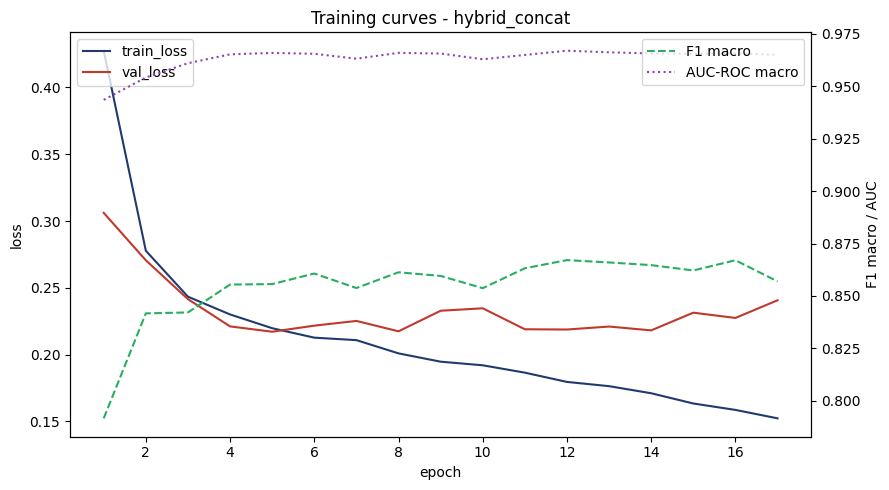

In [20]:
# Plot training and validation curves for the last seed executed.
x = range(1, len(history["train_loss"]) + 1)

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(x, history["train_loss"], label="train_loss", color="#1f3b6e")
ax1.plot(x, history["val_loss"], label="val_loss", color="#c0392b")
ax1.set_xlabel("epoch")
ax1.set_ylabel("loss")
ax1.legend(loc="upper left")

# Display validation F1-macro and AUC-ROC on a secondary axis.
ax2 = ax1.twinx()
ax2.plot(x, history["val_f1_macro"], label="F1 macro", color="#27ae60", ls="--")
ax2.plot(x, history["val_auc_macro"], label="AUC-ROC macro", color="#8e44ad",
         ls=":")
ax2.set_ylabel("F1 macro / AUC")
ax2.legend(loc="upper right")

plt.title(f"Training curves - {ARCH_NAME}")
plt.tight_layout()
plt.show()